In [2]:
import numpy as np
import pandas as pd
import scipy.sparse as sparse
import itertools
import matplotlib
from matplotlib import cm
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, LinearSegmentedColormap
from datetime import date
import re
# from tqdm import tqdm
import time
# from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr, rankdata, describe, mode, fisher_exact
import scipy as sp
import scipy.stats as stats
from scipy.spatial.distance import jaccard, euclidean, cosine, pdist
# import functools
# import operator
import gzip
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances
from sklearn.metrics import pairwise_distances
import sys
import os
from functools import partial
from contextlib import closing
from multiprocessing import Pool
import re
import h5py
import tabix
import upsetplot
from wordcloud import WordCloud
from sklearn.decomposition import NMF, non_negative_factorization
from collections import Counter
from scipy.stats import hypergeom
from scipy.stats.mstats import gmean
from scipy.cluster import hierarchy
import squarify
try:
    import piplite
    await piplite.install(['ipywidgets'])
except ImportError:
    pass
import ipywidgets as widgets
import json
from subprocess import Popen, PIPE
import requests

today = date.today()

**Functions**

In [9]:
# order = 4
# datadir = '/home/ctrader/region_similarity/data/rank_based/hilbert/'
# in_f = datadir + 'hilbert_regions_order_{}_CT20230606.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.hdf5'.format(order)

# hdf5_f = h5py.File(in_f, 'r')
# order_4_coords = np.char.decode(hdf5_f['coordinates'][:])
# hdf5_f.close()

In [114]:
# order = 7
# datadir = '/home/ctrader/region_similarity/data/rank_based/hilbert/'
# in_f = datadir + 'hilbert_regions_order_{}_CT20230606.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.hdf5'.format(order)

# hdf5_f = h5py.File(in_f, 'r')
# order_7_coords = np.char.decode(hdf5_f['coordinates'][:])
# hdf5_f.close()

In [2]:
chr_start_ind_dict = {}
for order in [4, 5, 6, 7, 8, 9, 10, 11]:
    print(order)
    datadir = '/home/ctrader/region_similarity/data/rank_based/hilbert/'
    in_f = datadir + 'hilbert_regions_order_{}_CT20230606.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.hdf5'.format(order)

    hdf5_f = h5py.File(in_f, 'r')
    order_coords = np.char.decode(hdf5_f['coordinates'][:])
    hdf5_f.close()
    
    chr_start_ind_dict[order] = np.unique(order_coords[:, 0], return_index=True)[1]

4
5
6
7
8
9
10
11


In [3]:
"""
Converts hilbert curve inds across scales. Takes in a starting order, a starting segment index, 
and a desired hilbert order. Returns the overlapping indices in the desired order
"""
def order_ind_conv(start_ind, start_o, end_o):
    # difference in orders
    o_diff = end_o - start_o
    # relative size of starting segment to ending segment
    seg_multiplier = 4**o_diff

    # find chromosome offset values for each order
    # due to non-linear differences in number of segments per chromosome
    offset_mask = chr_start_ind_dict[start_o] <= start_ind
    start_o_offset = chr_start_ind_dict[start_o][offset_mask][-1]
    end_o_offset = chr_start_ind_dict[end_o][offset_mask][-1]

    # correct starting ind
    start_ind_offset = start_ind - start_o_offset
    
    # find mapped end inds
    end_inds_offset = np.arange((seg_multiplier * start_ind_offset), (seg_multiplier * (start_ind_offset + 1)), dtype=int)
    # correct end inds
    end_inds = end_inds_offset + end_o_offset
    
    return end_inds

In [4]:
order_ind_conv(2810, 4, 7)

array([179136, 179137, 179138, 179139, 179140, 179141, 179142, 179143,
       179144, 179145, 179146, 179147, 179148, 179149, 179150, 179151,
       179152, 179153, 179154, 179155, 179156, 179157, 179158, 179159,
       179160, 179161, 179162, 179163, 179164, 179165, 179166, 179167,
       179168, 179169, 179170, 179171, 179172, 179173, 179174, 179175,
       179176, 179177, 179178, 179179, 179180, 179181, 179182, 179183,
       179184, 179185, 179186, 179187, 179188, 179189, 179190, 179191,
       179192, 179193, 179194, 179195, 179196, 179197, 179198, 179199])

**Data**

In [14]:
# example_data = []
# for i in range(0, 1048576, 2000):
#     example_data.append(['chr1', str(i), str(i+1), 'test1'])
# for i in range(0, 1048576, 3000):
#     example_data.append(['chr1', str(i), str(i+1), 'test2'])
    
# for i in range(1048576, 1048576 * 2, 4000):
#     example_data.append(['chr1', str(i), str(i+1), 'test1'])
# for i in range(1048576, 1048576 * 2, 2000):
#     example_data.append(['chr1', str(i), str(i+1), 'test2'])
    
# for i in range(1048576 *2 , 1048576 * 3, 8000):
#     example_data.append(['chr1', str(i), str(i+1), 'test1'])
# for i in range(1048576 * 2, 1048576 * 3, 1000):
#     example_data.append(['chr1', str(i), str(i+1), 'test2'])

In [17]:
# np.savetxt('/home/ctrader/hilbert/data/test/testdata_CT20230620.bed', example_data, fmt='%s', delimiter='\t')

In [21]:
def load_factors(per_f):
    hdf5_f = h5py.File(per_f, 'r')
    factors = np.char.decode(hdf5_f['factors'][:])
    color = np.char.decode(hdf5_f['colors'][:])
    hdf5_f.close()
    return factors, color

datadir = '/home/ctrader/region_similarity/data/rank_based/'
DHS_per_f = datadir + 'regions_1kb_CT20230427.DHS.factornormNMF.sum_enrich_corank_percentile.hdf5'
epi_per_f = datadir + 'regions_1kb_CT20230427.epilogos.statesum_rank_percentile.hdf5'

# load region percentiles
DHS_factors, DHS_color = load_factors(DHS_per_f)
epi_factors, epi_color = load_factors(epi_per_f)

factor_order = np.append(DHS_factors, epi_factors)
color_order = np.append(DHS_color, epi_color)

color_order[np.where(factor_order == 'Quies')[0]] = '#e0e0e0'

**Narration rank results**

In [59]:
# all_order_sparsity = []

all_order_top_factor_regions = {}
for order in [4, 5, 6, 7, 8, 9, 10, 11]:
    print(order)
    datadir = '/home/ctrader/region_similarity/data/rank_based/hilbert/'
    in_f = datadir + 'hilbert_regions_order_{}_CT20230606.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.hdf5'.format(order)

    hdf5_f = h5py.File(in_f, 'r')
    order_ranks = hdf5_f['percentiles'][:]
    order_coords = np.char.decode(hdf5_f['coordinates'][:])
    hdf5_f.close()
    
    
    top_factor_regions = order_coords[np.argmax(order_ranks, axis=0)]
    order_dict = {}
    for r, factor in zip(top_factor_regions, range(len(top_factor_regions))):
        region = r[0] + ':' + r[1] + '-' + r[2]
        order_dict[factor] = region
    all_order_top_factor_regions[order] = order_dict
    
#     sparsity = np.count_nonzero(order_ranks, axis=0) / len(order_ranks)
#     all_order_sparsity.append(sparsity)
    
# all_order_sparsity = np.array(all_order_sparsity)

4
5
6
7
8
9
10
11


In [61]:
datadir = '/home/ctrader/region_similarity/data/rank_based/hilbert'
filepath = os.path.join(datadir, 'hilbert_orders_4t11.top_regions_per_factor.CT20230626.json')
with open(filepath, 'w') as file:
    json.dump(all_order_top_factor_regions, file)

In [57]:
    top_factor_regions = order_coords[np.argmax(order_ranks, axis=0)]

    order_dict = {}
    for r, factor in zip(top_factor_regions, range(len(top_factor_regions))):
        region = r[0] + ':' + r[1] + '-' + r[2]
        order_dict[factor] = region

In [58]:
order_dict

{0: 'chr19:52428800-53477376',
 1: 'chr6:32505856-33554432',
 2: 'chr6:6291456-7340032',
 3: 'chr4:173015040-174063616',
 4: 'chr10:128974848-130023424',
 5: 'chr15:38797312-39845888',
 6: 'chr1:29360128-30408704',
 7: 'chr5:88080384-89128960',
 8: 'chr18:22020096-23068672',
 9: 'chr15:38797312-39845888',
 10: 'chr9:115343360-116391936',
 11: 'chr7:46137344-47185920',
 12: 'chr1:152043520-153092096',
 13: 'chr18:75497472-76546048',
 14: 'chr7:1048576-2097152',
 15: 'chr19:57671680-58617616',
 16: 'chr11:65011712-66060288',
 17: 'chr6:27262976-28311552',
 18: 'chr11:65011712-66060288',
 19: 'chr9:136314880-137363456',
 20: 'chr22:40894464-41943040',
 21: 'chr1:155189248-156237824',
 22: 'chr19:1048576-2097152',
 23: 'chr19:1048576-2097152',
 24: 'chr14:68157440-69206016',
 25: 'chr14:68157440-69206016',
 26: 'chr16:84934656-85983232',
 27: 'chr19:36700160-37748736',
 28: 'chr19:22020096-23068672',
 29: 'chr7:26214400-27262976',
 30: 'chr12:53477376-54525952',
 31: 'chr10:100663296-10171

Text(0.5, 0.92, 'Factor Density at Each Order')

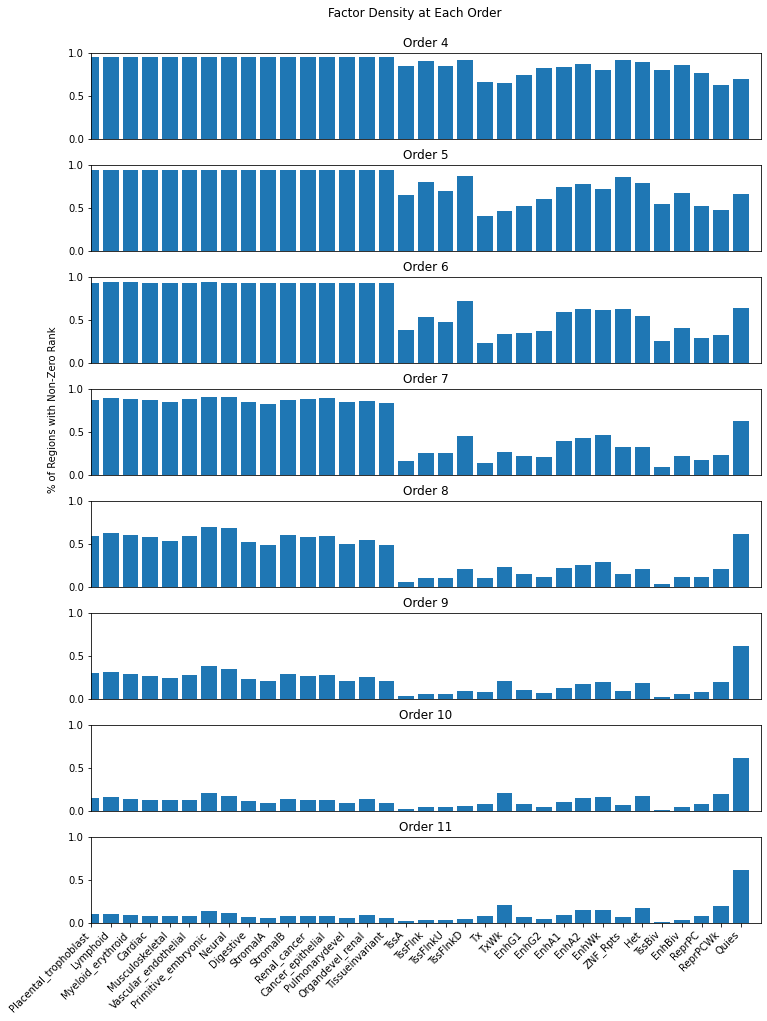

In [37]:
# bar chart showing sparsity of each factor at each order
fig, axes = plt.subplots(len(all_order_sparsity), 1, figsize=(12, 16))  
fig.patch.set_facecolor('white')
plt.subplots_adjust(hspace=0.3)

axes.ravel()

for ax, sparsity, order in zip(axes, all_order_sparsity, np.arange(4, 12)):
    ax.bar(np.arange(len(sparsity)), sparsity)
    
#     if scale == '1':
#         ax.legend(['Full Dataset', 'Subset Search Space'], loc=(0.79, 1.01))
    
    ax.set_ylim([0, 1])
    ax.set_xlim([0, len(sparsity)])
    
    ax.set_yticks([0, 0.5, 1])
    
    ax.set_xticks([])
    ax.set_title('Order ' + str(order))
    
axes[-1].set_xticks(np.arange(len(factor_order)))
axes[-1].set_xticklabels(factor_order, rotation=45, ha='right')

fig.text(0.075, 0.5, '% of Regions with Non-Zero Rank', rotation=90)



fig.suptitle('Factor Density at Each Order', y=0.92)

**SFC results**

In [ ]:
# checking to make sure parallelization results match results from before

In [145]:
chrm='Y'

datadir = '/home/ctrader/hilbert/results/TF/20230621/4'
f = open(os.path.join(datadir, 'chr{}.json'.format(chrm)))
after = json.load(f)
f.close()

datadir = '/home/ctrader/hilbert/results/TF/JQ/20230608'
f = open(os.path.join(datadir, 'chr{}.json'.format(chrm)))
before = json.load(f)
f.close()

In [146]:
b_c = before['chromosome']
b_o = before['order']
b_min = before['min']
b_max = before['max']
b_fields = before['fields']
b_dtype = before['dtype']
b_shape = before['shape']
b_size = before['size']
b_bytes = before['bytes']
b_bytes_per_value = before['bytes_per_value']

a_c = after['chromosome']
a_o = after['order']
a_min = after['min']
a_max = after['max']
a_fields = after['fields']
a_dtype = after['dtype']
a_shape = after['shape']
a_size = after['size']
a_bytes = after['bytes']
a_bytes_per_value = after['bytes_per_value']

In [147]:
print('chromosome\t', a_c==b_c)
print('order\t', a_o==b_o)
print('min\t', a_min[1:]==b_min)
print('max\t', a_max[1:]==b_max)
print('fields\t', a_fields[1:]==b_fields)
print('dtype\t', a_dtype==b_dtype)
print('bpv\t', a_bytes_per_value==b_bytes_per_value)
print()
print('shape\t', a_shape==b_shape, a_shape, b_shape)
print('size\t', a_size==b_size, a_size, b_size)
print('bytes\t', a_bytes==b_bytes, a_bytes, b_bytes)



chromosome	 True
order	 True
min	 True
max	 True
fields	 True
dtype	 True
bpv	 True

shape	 False [55, 283] [55, 282]
size	 False 15565 15510
bytes	 False 62260 62040


DHS

In [8]:
sfc = np.loadtxt('/home/ctrader/hilbert/results/DHS/20230622/order_12_windows_annotation_sfc_scores.txt.gz', skiprows=1, usecols=np.arange(3, 16+3), delimiter='\t', dtype=float)

In [ ]:
# kde plot showing the number of segments with a value at each order 
dhs_segment_fraction_nonzero = []
for order in range(4, 13):
    print(order)
    filename = '/home/ctrader/hilbert/results/DHS/20230622/order_{}_windows_annotation_sfc_scores.txt.gz'.format(order)
    sfc = np.loadtxt(filename, delimiter='\t', dtype=str)
    dhs_factors = sfc[0]
    sfc = sfc[1:, 3:].astype(float)
    segment_nonzero = np.count_nonzero(sfc > 0, axis=1)
    all_nonzero = np.count_nonzero(segment_nonzero) / len(segment_nonzero)
    dhs_segment_fraction_nonzero.append(all_nonzero)
dhs_segment_fraction_nonzero = np.array(dhs_segment_fraction_nonzero)

4
5
6
7
8
9
10
11


TF Motifs

In [ ]:
# kde plot showing the number of segments with a value at each order 
tf_segment_fraction_nonzero = []
for order in range(4, 11):
    print(order)
    filename = '/home/ctrader/hilbert/results/TF/20230622/order_{}_windows_annotation_sfc_scores.txt.gz'.format(order)
    sfc = np.loadtxt(filename, delimiter='\t', dtype=str)
    tf_factors = sfc[0]
    sfc = sfc[1:, 3:].astype(float)
    segment_nonzero = np.count_nonzero(sfc > 0, axis=1)
    all_nonzero = np.count_nonzero(segment_nonzero) / len(segment_nonzero)
    tf_segment_fraction_nonzero.append(all_nonzero)
tf_segment_fraction_nonzero = np.array(tf_segment_fraction_nonzero)

4
5
6
7
8
9


In [ ]:
# kde plot showing the number of segments with a value at each order 
tf_dhsmapped_segment_fraction_nonzero = []
for order in range(4, 11):
    print(order)
    filename = '/home/ctrader/hilbert/results/TFs_overlapping_DHS/20230622/order_{}_windows_annotation_sfc_scores.txt.gz'.format(order)
    sfc = np.loadtxt(filename, delimiter='\t', dtype=str)
    tf_factors = sfc[0]
    sfc = sfc[1:, 3:].astype(float)
    segment_nonzero = np.count_nonzero(sfc > 0, axis=1)
    all_nonzero = np.count_nonzero(segment_nonzero) / len(segment_nonzero)
    tf_dhsmapped_segment_fraction_nonzero.append(all_nonzero)
tf_dhsmapped_segment_fraction_nonzero = np.array(tf_dhsmapped_segment_fraction_nonzero)

In [5]:
# had trouble reading in order 9 TF file the normal way
order = 9
filename = '/home/jquon/hilbert_curve_sfc_20230601/tf_motifs/order_{}_windows_annotation_sfc_scores.txt.gz'.format(order)
f = open(filename, 'rb')
f = gzip.GzipFile(fileobj=f)
lines = f.readlines()
f.close()

# sfc = []
# for line in lines:
#     line = line.decode().strip().split('\t')
#     sfc.append(line)
# sfc = np.array(sfc)

# print('read')

# tf_factors = sfc[0]
# sfc = sfc[1:, 3:].astype(float)
# segment_nonzero = np.count_nonzero(sfc > 0, axis=1)
# all_nonzero = np.count_nonzero(segment_nonzero) / len(segment_nonzero)
# tf_segment_fraction_nonzero.append(all_nonzero)
# tf_segment_fraction_nonzero = np.array(tf_segment_fraction_nonzero)

In [154]:
# lines.decode()

Chromatin States

In [ ]:
# kde plot showing the number of segments with a value at each order 
cs_segment_fraction_nonzero = []
for order in range(4, 10):
    print(order)
    filename = '/home/jquon/hilbert_curve_sfc_20230601/chromatin_states/order_{}_windows_annotation_sfc_scores.txt.gz'.format(order)
    sfc = np.loadtxt(filename, delimiter='\t', dtype=str)
    cs_factors = sfc[0]
    sfc = sfc[1:, 3:].astype(float)
    segment_nonzero = np.count_nonzero(sfc > 0, axis=1)
    all_nonzero = np.count_nonzero(segment_nonzero) / len(segment_nonzero)
    cs_segment_fraction_nonzero.append(all_nonzero)
cs_segment_fraction_nonzero = np.array(cs_segment_fraction_nonzero)

Text(0.5, 1.0, 'Fraction of Hilbert Segments Containing Non-Zero SFC Data')

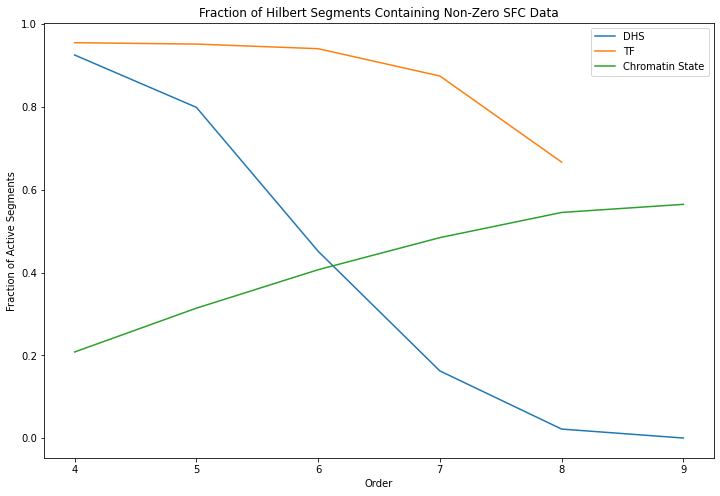

In [9]:
fig = plt.figure(figsize=(12, 8))  
fig.patch.set_facecolor('white')

plt.plot(range(4, 10), dhs_segment_fraction_nonzero)
plt.plot(range(4, 9), tf_segment_fraction_nonzero)
plt.plot(range(4, 10), cs_segment_fraction_nonzero)

plt.xlabel('Order')
plt.ylabel('Fraction of Active Segments')
plt.legend(['DHS', 'TF', 'Chromatin State'])
plt.title('Fraction of Hilbert Segments Containing Non-Zero SFC Data')

Creating -e file for chromatin states

In [10]:
# datadir = '/home/ctrader/chromatin_states/'
# filepath = os.path.join(datadir, 'state_counts_CT20230622.c2.txt')

# x = np.loadtxt(filepath, dtype=int)

In [12]:
# np.sum(x) / 833